In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# Menentukan lokasi folder utama proyek
BASE_DIR = Path.cwd().parent

# Lokasi data mentah dan hasil data bersih
RAW_PATH = BASE_DIR / "Data" / "raw" / "data_responden.csv"
CLEAN_DIR = BASE_DIR / "Data" / "Clean"

# Membuat folder clean jika belum tersedia
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

print("Lokasi data mentah:", RAW_PATH)
print("Lokasi penyimpanan:", CLEAN_DIR)

Lokasi data mentah: c:\Users\daniel\Desktop\Data Mining-SPK\Data\raw\data_responden.csv
Lokasi penyimpanan: c:\Users\daniel\Desktop\Data Mining-SPK\Data\Clean


## 1. Data Cleaning

Data mentah merupakan data hasil pengumpulan kuesioner melalui Google Forms. Sebelum digunakan, data perlu diperiksa untuk mengetahui jumlah responden, struktur kolom, dan kondisi awal dataset.

In [2]:
# Membaca dataset
df_raw = pd.read_csv(RAW_PATH)

# Menyalin data mentah untuk proses preparation
df = df_raw.copy()

print("Ukuran data mentah:", df.shape)

print("\nInformasi dataset:")
df.info()

print("\nLima data pertama:")
display(df.head())

print("\nJumlah missing value:")
display(df.isna().sum().to_frame("Jumlah Missing Value"))

Ukuran data mentah: (40, 30)

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 30 columns):
 #   Column                                                                                                        Non-Null Count  Dtype  
---  ------                                                                                                        --------------  -----  
 0   Timestamp                                                                                                     37 non-null     str    
 1   Semester saat ini                                                                                             37 non-null     str    
 2   Program Studi                                                                                                 37 non-null     str    
 3   Usia                                                                                                          37 non-null     str    
 4   Column 4            

,Timestamp,Semester saat ini,Program Studi,Usia,Column 4,Rata-rata berapa jam Anda tidur dalam sehari?,"Dalam satu minggu, berapa kali Anda melakukan aktivitas olahraga minimal 30 menit?",Seberapa teratur Anda makan dalam sehari?,"Dalam satu minggu, seberapa sering Anda melewatkan waktu makan karena kuliah, tugas, atau aktivitas lainnya?",Seberapa sering Anda merasa kelelahan secara fisik ketika menjalani aktivitas kuliah?,...,Berapa IPK Anda saat ini?,"Sejauh ini, kira-kira berapa persen tugas yang Anda kumpulkan tepat waktu?",Seberapa sering Anda berhasil menyelesaikan tugas sesuai target yang telah Anda tentukan?,"Seberapa sering keterlambatan tugas terjadi karena kelelahan, stres, atau kurang fokus?",Seberapa penting performa akademik sebagai indikator keberhasilan mahasiswa?,Seberapa penting gaya hidup sehat dalam mendukung performa akademik?,Seberapa penting kondisi mental dalam mendukung performa akademik?,Seberapa penting pola belajar dalam mendukung performa akademik?,Email Address,Column 24
0,10/1/2026 19:06:08,3-4,Teologi,21 Tahun,NaN,4-5 jam,2 kali,2.0,2.0,2.0,...,"3,00 - 3,49",80-89%,5.0,1.0,5.0,3.0,5.0,5.0,jenilitanggowa@gmail.com,NaN
1,10/1/2026 19:06:55,7 atau Lebih,Akuntansi,26,NaN,6-8 jam,2 kali,5.0,1.0,4.0,...,"3,00 - 3,49",80-89%,4.0,3.0,4.0,4.0,4.0,5.0,ekwivalen.2018ea146@civitas.ukrida.ac.id,NaN
2,10/1/2026 19:14:52,3-4,Management Bisnis,20,NaN,4-5 jam,4 kali atau lebih,3.0,4.0,3.0,...,"2,50 - 2,99",60-69%,5.0,1.0,5.0,5.0,5.0,5.0,hermansulaiman503@gmail.com,NaN
3,10/1/2026 19:16:16,3-4,Pendidikan Agama Katolik,22 Tahun,NaN,6-8 jam,1 kali,3.0,3.0,4.0,...,"3,00 - 3,49",90-100%,4.0,2.0,5.0,5.0,5.0,5.0,lusianauci376@gmail.com,NaN
4,10/1/2026 19:27:56,5-6,DIII KEPERAWATAN WAIKABUBAK,21,NaN,4-5 jam,4 kali atau lebih,5.0,4.0,4.0,...,"3,50 - 4,00",80-89%,4.0,4.0,4.0,4.0,4.0,5.0,shandabore883@gmail.com,NaN



Jumlah missing value:


,Jumlah Missing Value
Timestamp,3
Semester saat ini,3
Program Studi,3
Usia,3
Column 4,40
Rata-rata berapa jam Anda tidur dalam sehari?,3
"Dalam satu minggu, berapa kali Anda melakukan aktivitas olahraga minimal 30 menit?",3
Seberapa teratur Anda makan dalam sehari?,3
"Dalam satu minggu, seberapa sering Anda melewatkan waktu makan karena kuliah, tugas, atau aktivitas lainnya?",3
Seberapa sering Anda merasa kelelahan secara fisik ketika menjalani aktivitas kuliah?,3


### 1.1 Menghapus Data Kosong

Data kosong diperiksa untuk memastikan setiap baris benar-benar merupakan respons kuesioner. Kolom yang seluruh nilainya kosong juga dihapus karena tidak memberikan informasi untuk analisis.

In [3]:
# Membersihkan spasi pada nama kolom
df.columns = df.columns.astype(str).str.strip()

# Menghapus baris tanpa Timestamp
jumlah_awal = len(df)

if "Timestamp" in df.columns:
    df = df[df["Timestamp"].notna()].copy()

print("Baris kosong yang dihapus:", jumlah_awal - len(df))

# Menghapus kolom yang seluruh nilainya kosong
kolom_kosong = df.columns[df.isna().all()].tolist()

df.drop(columns=kolom_kosong, inplace=True)

print("Kolom kosong yang dihapus:", kolom_kosong)

# Menghapus kolom email jika tersedia
kolom_email = [
    col for col in df.columns
    if "email" in col.lower()
]

df.drop(columns=kolom_email, inplace=True)

print("Kolom email yang dihapus:", kolom_email)

print("\nUkuran data setelah cleaning:", df.shape)

display(df.head())

Baris kosong yang dihapus: 3
Kolom kosong yang dihapus: ['Column 4', 'Column 24']
Kolom email yang dihapus: ['Email Address']

Ukuran data setelah cleaning: (37, 27)


,Timestamp,Semester saat ini,Program Studi,Usia,Rata-rata berapa jam Anda tidur dalam sehari?,"Dalam satu minggu, berapa kali Anda melakukan aktivitas olahraga minimal 30 menit?",Seberapa teratur Anda makan dalam sehari?,"Dalam satu minggu, seberapa sering Anda melewatkan waktu makan karena kuliah, tugas, atau aktivitas lainnya?",Seberapa sering Anda merasa kelelahan secara fisik ketika menjalani aktivitas kuliah?,Seberapa sering Anda merasa stres akibat tuntutan akademik?,...,Seberapa sering Anda mengerjakan tugas hanya ketika mendekati deadline?,Seberapa sering Anda menunda pengerjaan tugas atau kegiatan belajar?,Berapa IPK Anda saat ini?,"Sejauh ini, kira-kira berapa persen tugas yang Anda kumpulkan tepat waktu?",Seberapa sering Anda berhasil menyelesaikan tugas sesuai target yang telah Anda tentukan?,"Seberapa sering keterlambatan tugas terjadi karena kelelahan, stres, atau kurang fokus?",Seberapa penting performa akademik sebagai indikator keberhasilan mahasiswa?,Seberapa penting gaya hidup sehat dalam mendukung performa akademik?,Seberapa penting kondisi mental dalam mendukung performa akademik?,Seberapa penting pola belajar dalam mendukung performa akademik?
0,10/1/2026 19:06:08,3-4,Teologi,21 Tahun,4-5 jam,2 kali,2.0,2.0,2.0,4.0,...,2.0,1.0,"3,00 - 3,49",80-89%,5.0,1.0,5.0,3.0,5.0,5.0
1,10/1/2026 19:06:55,7 atau Lebih,Akuntansi,26,6-8 jam,2 kali,5.0,1.0,4.0,3.0,...,4.0,4.0,"3,00 - 3,49",80-89%,4.0,3.0,4.0,4.0,4.0,5.0
2,10/1/2026 19:14:52,3-4,Management Bisnis,20,4-5 jam,4 kali atau lebih,3.0,4.0,3.0,1.0,...,5.0,2.0,"2,50 - 2,99",60-69%,5.0,1.0,5.0,5.0,5.0,5.0
3,10/1/2026 19:16:16,3-4,Pendidikan Agama Katolik,22 Tahun,6-8 jam,1 kali,3.0,3.0,4.0,2.0,...,3.0,3.0,"3,00 - 3,49",90-100%,4.0,2.0,5.0,5.0,5.0,5.0
4,10/1/2026 19:27:56,5-6,DIII KEPERAWATAN WAIKABUBAK,21,4-5 jam,4 kali atau lebih,5.0,4.0,4.0,3.0,...,4.0,3.0,"3,50 - 4,00",80-89%,4.0,4.0,4.0,4.0,4.0,5.0


### 1.2 Menghapus Data Duplikat

Pemeriksaan duplikasi dilakukan untuk mengetahui apakah terdapat baris respons yang sama persis. Data duplikat dapat menyebabkan perhitungan menjadi tidak akurat apabila dihitung lebih dari satu kali.

In [4]:
# Menghitung jumlah data duplikat
jumlah_duplikat = df.duplicated().sum()

print("Jumlah data duplikat:", jumlah_duplikat)

# Menghapus data duplikat jika ditemukan
if jumlah_duplikat > 0:
    df = df.drop_duplicates().copy()
    print("Data duplikat berhasil dihapus.")
else:
    print("Tidak ditemukan data duplikat.")

print("\nUkuran data setelah pemeriksaan:", df.shape)

Jumlah data duplikat: 0
Tidak ditemukan data duplikat.

Ukuran data setelah pemeriksaan: (37, 27)


### 1.3 Pemeriksaan Missing Value

Missing value merupakan kondisi ketika terdapat jawaban yang kosong pada suatu kolom. Pemeriksaan dilakukan untuk mengetahui jumlah jawaban yang belum terisi pada setiap pertanyaan.

In [5]:
# Menghitung missing value
missing_value = df.isna().sum()

missing_report = pd.DataFrame({
    "Jumlah Missing": missing_value,
    "Persentase (%)": (missing_value / len(df) * 100).round(2)
})

display(missing_report)

# Menghitung jumlah baris yang memiliki nilai kosong
baris_missing = df.isna().any(axis=1).sum()

print("Jumlah baris dengan missing value:", baris_missing)

,Jumlah Missing,Persentase (%)
Timestamp,0,0.0
Semester saat ini,0,0.0
Program Studi,0,0.0
Usia,0,0.0
Rata-rata berapa jam Anda tidur dalam sehari?,0,0.0
"Dalam satu minggu, berapa kali Anda melakukan aktivitas olahraga minimal 30 menit?",0,0.0
Seberapa teratur Anda makan dalam sehari?,0,0.0
"Dalam satu minggu, seberapa sering Anda melewatkan waktu makan karena kuliah, tugas, atau aktivitas lainnya?",0,0.0
Seberapa sering Anda merasa kelelahan secara fisik ketika menjalani aktivitas kuliah?,0,0.0
Seberapa sering Anda merasa stres akibat tuntutan akademik?,0,0.0


Jumlah baris dengan missing value: 0


### 1.4 Pemeriksaan Noise dan Inkonsistensi

Pemeriksaan dilakukan untuk menemukan nilai yang tidak sesuai dengan format jawaban kuesioner. Pada pertanyaan Likert, nilai yang valid berada pada rentang 1 sampai 5.

In [6]:
# Mencari kolom pertanyaan Likert
likert_cols = [
    col for col in df.columns
    if any(kata in col.lower() for kata in [
        "teratur anda makan",
        "melewatkan waktu makan",
        "kelelahan secara fisik",
        "merasa stres",
        "merasa cemas",
        "kesulitan berkonsentrasi",
        "merasa kewalahan",
        "sulit beristirahat",
        "jadwal belajar",
        "mendekati deadline",
        "menunda pengerjaan tugas",
        "menyelesaikan tugas sesuai target",
        "keterlambatan tugas terjadi karena"
    ])
]

# Mengubah jawaban Likert menjadi numerik
for col in likert_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Memeriksa nilai di luar rentang 1-5
invalid_report = {}

for col in likert_cols:
    invalid = df[col].notna() & ~df[col].between(1, 5)
    invalid_report[col] = invalid.sum()

display(
    pd.Series(invalid_report, name="Jumlah Nilai Tidak Valid")
    .to_frame()
)

print("Total nilai tidak valid:", sum(invalid_report.values()))

,Jumlah Nilai Tidak Valid
Seberapa teratur Anda makan dalam sehari?,0
"Dalam satu minggu, seberapa sering Anda melewatkan waktu makan karena kuliah, tugas, atau aktivitas lainnya?",0
Seberapa sering Anda merasa kelelahan secara fisik ketika menjalani aktivitas kuliah?,0
Seberapa sering Anda merasa stres akibat tuntutan akademik?,0
Seberapa sering Anda merasa cemas ketika menghadapi tugas atau ujian?,0
Seberapa sering Anda merasa kesulitan berkonsentrasi karena tekanan atau pikiran yang mengganggu?,0
Seberapa sering Anda merasa kewalahan dengan jumlah tugas atau kegiatan kuliah?,0
Seberapa sering Anda merasa sulit beristirahat karena memikirkan tugas atau kegiatan akademik?,0
Seberapa konsisten Anda memiliki jadwal belajar mandiri?,0
Seberapa sering Anda belajar hanya ketika mendekati deadline atau ujian?,0


Total nilai tidak valid: 0


## 2. Data Transformation

Transformasi data dilakukan dengan mengubah jawaban kategorikal menjadi nilai numerik. Selain itu, dilakukan reverse scoring pada pertanyaan negatif agar seluruh indikator memiliki arah penilaian yang sama, yaitu semakin tinggi skor berarti semakin baik kondisinya.

In [7]:
# Pemetaan kategori durasi tidur
sleep_map = {
    "Kurang dari 4 jam": 1,
    "<4 jam": 1,
    "4-5 jam": 2,
    "4–5 jam": 2,
    "5-6 jam": 3,
    "5–6 jam": 3,
    "6-8 jam": 4,
    "6–8 jam": 4,
    "Lebih dari 8 jam": 3,
    ">8 jam": 3
}

# Pemetaan frekuensi olahraga
exercise_map = {
    "Tidak pernah": 1,
    "1 kali": 2,
    "2 kali": 3,
    "3 kali": 4,
    "4 kali atau lebih": 5
}

# Pemetaan durasi belajar
study_duration_map = {
    "Kurang dari 30 menit": 1,
    "30-60 menit": 2,
    "30–60 menit": 2,
    "1-2 jam": 3,
    "1–2 jam": 3,
    "2-3 jam": 4,
    "2–3 jam": 4,
    "Lebih dari 3 jam": 5
}

# Pemetaan IPK
gpa_map = {
    "Belum memiliki IPK": np.nan,
    "< 2,00": 1,
    "Di bawah 2,00": 1,
    "2,00 - 2,49": 2,
    "2,00–2,49": 2,
    "2,50 - 2,99": 3,
    "2,50–2,99": 3,
    "3,00 - 3,49": 4,
    "3,00–3,49": 4,
    "3,50 - 4,00": 5,
    "3,50–4,00": 5
}

# Pemetaan persentase tugas tepat waktu
ontime_map = {
    "<50%": 1,
    "Di bawah 50%": 1,
    "50-59%": 2,
    "50–59%": 2,
    "60-69%": 3,
    "60–69%": 3,
    "70-79%": 4,
    "70–79%": 4,
    "80-89%": 5,
    "80–89%": 5,
    "90-100%": 5,
    "90–100%": 5
}

def clean_text(series):
    return series.astype("string").str.strip()

print("Pemetaan kategori berhasil disiapkan.")

Pemetaan kategori berhasil disiapkan.


8.1 Menentukan kolom pertanyaan
Karena nama kolom Google Forms cukup panjang, kita gunakan fungsi find_col() untuk mencari kolom berdasarkan sebagian teks pertanyaannya.

In [8]:
def find_col(fragment):
    matches = [
        col for col in df.columns
        if fragment.lower() in col.lower()
    ]

    if not matches:
        raise KeyError(
            f"Kolom tidak ditemukan: {fragment}"
        )

    if len(matches) > 1:
        raise ValueError(
            f"Lebih dari satu kolom cocok: {fragment} -> {matches}"
        )

    return matches[0]

# C1 - Jasmani
col_sleep = find_col("berapa jam Anda tidur")
col_exercise = find_col("berapa kali Anda melakukan aktivitas olahraga")
col_meals = find_col("Seberapa teratur Anda makan")
col_skip = find_col("melewatkan waktu makan")
col_fatigue = find_col("kelelahan secara fisik")

# C2 - Mental
col_stress = find_col("merasa stres akibat")
col_anxiety = find_col("merasa cemas")
col_concentration = find_col("kesulitan berkonsentrasi")
col_overwhelmed = find_col("merasa kewalahan")
col_rest = find_col("sulit beristirahat")

# C3 - Pola Belajar
col_study_duration = find_col("berapa lama Anda belajar secara mandiri")
col_study_consistency = find_col("konsisten Anda memiliki jadwal belajar")
col_study_near_deadline = find_col("belajar hanya ketika mendekati")
col_task_near_deadline = find_col("mengerjakan tugas hanya ketika mendekati")
col_procrastination = find_col("menunda pengerjaan tugas")

# C4 - Akademik
col_gpa = find_col("Berapa IPK Anda")
col_on_time = find_col("berapa persen tugas yang Anda kumpulkan tepat waktu")
col_target = find_col("menyelesaikan tugas sesuai target")
col_late_reason = find_col("keterlambatan tugas terjadi karena")

print("Seluruh kolom indikator berhasil ditemukan.")

Seluruh kolom indikator berhasil ditemukan.


8.2 Mengubah data menjadi numerik

In [9]:
trans = pd.DataFrame(index=df.index)

# C1 - Jasmani
trans["sleep_score"] = clean_text(df[col_sleep]).map(sleep_map)
trans["exercise_score"] = clean_text(df[col_exercise]).map(exercise_map)
trans["meal_regularity"] = pd.to_numeric(df[col_meals], errors="coerce")
trans["skip_meals_raw"] = pd.to_numeric(df[col_skip], errors="coerce")
trans["fatigue_raw"] = pd.to_numeric(df[col_fatigue], errors="coerce")

# C2 - Mental
trans["stress_raw"] = pd.to_numeric(df[col_stress], errors="coerce")
trans["anxiety_raw"] = pd.to_numeric(df[col_anxiety], errors="coerce")
trans["concentration_raw"] = pd.to_numeric(df[col_concentration], errors="coerce")
trans["overwhelmed_raw"] = pd.to_numeric(df[col_overwhelmed], errors="coerce")
trans["rest_difficulty_raw"] = pd.to_numeric(df[col_rest], errors="coerce")

# C3 - Pola Belajar
trans["study_duration_score"] = clean_text(
    df[col_study_duration]
).map(study_duration_map)

trans["study_consistency"] = pd.to_numeric(
    df[col_study_consistency], errors="coerce"
)

trans["study_near_deadline_raw"] = pd.to_numeric(
    df[col_study_near_deadline], errors="coerce"
)

trans["task_near_deadline_raw"] = pd.to_numeric(
    df[col_task_near_deadline], errors="coerce"
)

trans["procrastination_raw"] = pd.to_numeric(
    df[col_procrastination], errors="coerce"
)

# C4 - Akademik
trans["gpa_score"] = clean_text(df[col_gpa]).map(gpa_map)

trans["ontime_score"] = clean_text(
    df[col_on_time]
).map(ontime_map)

trans["task_target"] = pd.to_numeric(
    df[col_target], errors="coerce"
)

trans["late_reason_raw"] = pd.to_numeric(
    df[col_late_reason], errors="coerce"
)

print("Transformasi data selesai.")
display(trans.head())

Transformasi data selesai.


,sleep_score,exercise_score,meal_regularity,skip_meals_raw,fatigue_raw,stress_raw,anxiety_raw,concentration_raw,overwhelmed_raw,rest_difficulty_raw,study_duration_score,study_consistency,study_near_deadline_raw,task_near_deadline_raw,procrastination_raw,gpa_score,ontime_score,task_target,late_reason_raw
0,2,3,2.0,2.0,2.0,4.0,3.0,2.0,1.0,2.0,2.0,3.0,2.0,2.0,1.0,4.0,5,5.0,1.0
1,4,3,5.0,1.0,4.0,3.0,3.0,2.0,4.0,2.0,3.0,3.0,4.0,4.0,4.0,4.0,5,4.0,3.0
2,2,5,3.0,4.0,3.0,1.0,2.0,3.0,1.0,3.0,1.0,3.0,4.0,5.0,2.0,3.0,3,5.0,1.0
3,4,2,3.0,3.0,4.0,2.0,2.0,2.0,3.0,2.0,1.0,3.0,3.0,3.0,3.0,4.0,5,4.0,2.0
4,2,5,5.0,4.0,4.0,3.0,3.0,3.0,1.0,3.0,1.0,3.0,4.0,4.0,3.0,5.0,5,4.0,4.0


8.3 Reverse scoring
Untuk pertanyaan negatif, semakin tinggi jawaban awal justru menunjukkan kondisi yang semakin buruk. Karena itu, skornya dibalik menggunakan rumus:
\[
X' = 6-X
\]

In [10]:
# Kolom pertanyaan negatif yang perlu dibalik
negative_cols = [
    "skip_meals_raw",
    "fatigue_raw",
    "stress_raw",
    "anxiety_raw",
    "concentration_raw",
    "overwhelmed_raw",
    "rest_difficulty_raw",
    "study_near_deadline_raw",
    "task_near_deadline_raw",
    "procrastination_raw",
    "late_reason_raw"
]

# Melakukan reverse scoring
for col in negative_cols:
    new_col = col.replace("_raw", "_score")
    trans[new_col] = 6 - trans[col]

print("Reverse scoring selesai.")
display(trans.head())

Reverse scoring selesai.


,sleep_score,exercise_score,meal_regularity,skip_meals_raw,fatigue_raw,stress_raw,anxiety_raw,concentration_raw,overwhelmed_raw,rest_difficulty_raw,...,fatigue_score,stress_score,anxiety_score,concentration_score,overwhelmed_score,rest_difficulty_score,study_near_deadline_score,task_near_deadline_score,procrastination_score,late_reason_score
0,2,3,2.0,2.0,2.0,4.0,3.0,2.0,1.0,2.0,...,4.0,2.0,3.0,4.0,5.0,4.0,4.0,4.0,5.0,5.0
1,4,3,5.0,1.0,4.0,3.0,3.0,2.0,4.0,2.0,...,2.0,3.0,3.0,4.0,2.0,4.0,2.0,2.0,2.0,3.0
2,2,5,3.0,4.0,3.0,1.0,2.0,3.0,1.0,3.0,...,3.0,5.0,4.0,3.0,5.0,3.0,2.0,1.0,4.0,5.0
3,4,2,3.0,3.0,4.0,2.0,2.0,2.0,3.0,2.0,...,2.0,4.0,4.0,4.0,3.0,4.0,3.0,3.0,3.0,4.0
4,2,5,5.0,4.0,4.0,3.0,3.0,3.0,1.0,3.0,...,2.0,3.0,3.0,3.0,5.0,3.0,2.0,2.0,3.0,2.0


8.4 Pemeriksaan hasil transformasi

In [11]:
print("Ukuran data hasil transformasi:", trans.shape)

print("\nJumlah missing value:")
display(trans.isna().sum().to_frame("Missing Value"))

print("\nStatistik deskriptif:")
display(trans.describe().T)

Ukuran data hasil transformasi: (37, 30)

Jumlah missing value:


,Missing Value
sleep_score,0
exercise_score,0
meal_regularity,0
skip_meals_raw,0
fatigue_raw,0
stress_raw,0
anxiety_raw,0
concentration_raw,0
overwhelmed_raw,0
rest_difficulty_raw,0



Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
sleep_score,37.0,3.081081,0.795067,2.0,2.0,3.0,4.0,4.0
exercise_score,37.0,2.459459,1.095308,1.0,2.0,2.0,3.0,5.0
meal_regularity,37.0,3.648649,1.110961,2.0,3.0,4.0,5.0,5.0
skip_meals_raw,37.0,2.783784,1.293899,1.0,2.0,3.0,4.0,5.0
fatigue_raw,37.0,3.648649,0.977986,1.0,3.0,4.0,4.0,5.0
stress_raw,37.0,3.405405,1.189292,1.0,3.0,4.0,4.0,5.0
anxiety_raw,37.0,3.540541,1.168917,1.0,3.0,4.0,4.0,5.0
concentration_raw,37.0,3.513514,1.193073,1.0,3.0,3.0,5.0,5.0
overwhelmed_raw,37.0,3.432432,1.214279,1.0,3.0,4.0,4.0,5.0
rest_difficulty_raw,37.0,3.027027,1.279898,1.0,2.0,3.0,4.0,5.0


# 9. Pembentukan skor kriteria C1–C4

3. Pembentukan Skor Kriteria

Setelah transformasi, beberapa indikator dikelompokkan menjadi empat kriteria utama, yaitu jasmani, mental, pola belajar, dan performa akademik. Skor setiap kriteria dihitung menggunakan rata-rata indikator yang termasuk di dalamnya.

In [12]:
criteria = pd.DataFrame(index=trans.index)

# C1 - Jasmani
criteria["C1_Jasmani"] = trans[
    [
        "sleep_score",
        "exercise_score",
        "meal_regularity",
        "skip_meals_score",
        "fatigue_score"
    ]
].mean(axis=1)

# C2 - Mental
criteria["C2_Mental"] = trans[
    [
        "stress_score",
        "anxiety_score",
        "concentration_score",
        "overwhelmed_score",
        "rest_difficulty_score"
    ]
].mean(axis=1)

# C3 - Pola Belajar
criteria["C3_Pola_Belajar"] = trans[
    [
        "study_duration_score",
        "study_consistency",
        "study_near_deadline_score",
        "task_near_deadline_score",
        "procrastination_score"
    ]
].mean(axis=1)

# C4 - Performa Akademik
criteria["C4_Akademik"] = trans[
    [
        "gpa_score",
        "ontime_score",
        "task_target",
        "late_reason_score"
    ]
].mean(axis=1)

print("Hasil skor kriteria:")
display(criteria.head())

print("\nStatistik skor kriteria:")
display(criteria.describe().T)

Hasil skor kriteria:


,C1_Jasmani,C2_Mental,C3_Pola_Belajar,C4_Akademik
0,3.0,3.6,3.6,4.75
1,3.8,3.2,2.4,4.00
2,3.0,4.0,2.2,4.00
3,2.8,3.8,2.6,4.25
4,3.2,3.4,2.2,4.00



Statistik skor kriteria:


,count,mean,std,min,25%,50%,75%,max
C1_Jasmani,37.0,2.951351,0.560566,1.600000,2.8,3.0,3.20,4.0
C2_Mental,37.0,2.616216,1.021305,1.000000,2.0,2.4,3.40,5.0
C3_Pola_Belajar,37.0,2.450000,0.692018,1.200000,2.0,2.2,3.00,4.0
C4_Akademik,37.0,4.349099,0.488225,3.333333,4.0,4.5,4.75,5.0


# 10. Deteksi outlier menggunakan IQR

4. Outlier Handling

Outlier merupakan nilai yang memiliki jarak cukup jauh dibandingkan sebagian besar data. Pada tahap ini, deteksi dilakukan menggunakan metode Interquartile Range (IQR). Nilai yang terdeteksi tidak langsung dihapus karena perlu diperiksa terlebih dahulu apakah nilai tersebut merupakan kesalahan atau memang jawaban responden yang valid.

In [13]:
def iqr_outlier_report(data):
    results = []

    for col in data.columns:
        values = data[col].dropna()

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)

        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        jumlah = (
            (values < lower) | (values > upper)
        ).sum()

        results.append({
            "Kriteria": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Batas Bawah": lower,
            "Batas Atas": upper,
            "Jumlah Outlier": jumlah
        })

    return pd.DataFrame(results)

outlier_report = iqr_outlier_report(criteria)

display(outlier_report)

,Kriteria,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier
0,C1_Jasmani,2.8,3.20,0.40,2.200,3.800,5
1,C2_Mental,2.0,3.40,1.40,-0.100,5.500,0
2,C3_Pola_Belajar,2.0,3.00,1.00,0.500,4.500,0
3,C4_Akademik,4.0,4.75,0.75,2.875,5.875,0


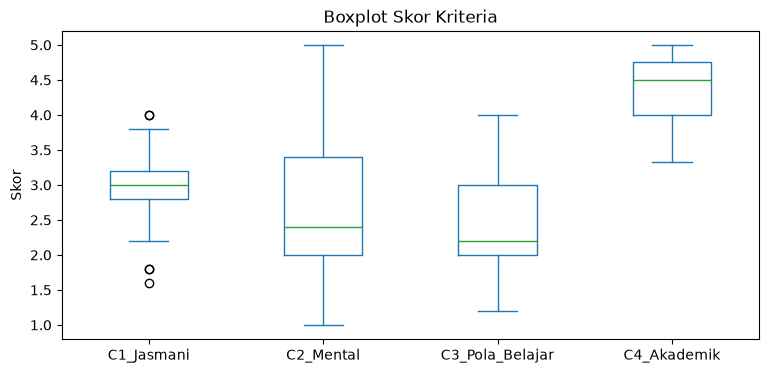

In [14]:
criteria.plot(
    kind="box",
    figsize=(9, 4),
    title="Boxplot Skor Kriteria"
)

plt.ylabel("Skor")
plt.show()

11. Menyimpan hasil data preparation

In [15]:
# Menghapus data yang tidak memiliki skor lengkap
analysis = criteria.dropna(
    subset=[
        "C1_Jasmani",
        "C2_Mental",
        "C3_Pola_Belajar",
        "C4_Akademik"
    ]
).copy()

print("Jumlah data sebelum seleksi:", len(criteria))
print("Jumlah data setelah seleksi:", len(analysis))
print("Data yang dikeluarkan:", len(criteria) - len(analysis))

# Menyimpan hasil
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(
    CLEAN_DIR / "data_clean.csv",
    index=False
)

trans.to_csv(
    CLEAN_DIR / "hasil_transformasi.csv",
    index=False
)

analysis.to_csv(
    CLEAN_DIR / "hasil_skor_kriteria.csv",
    index=False
)

print("\nFile berhasil disimpan:")
print(CLEAN_DIR / "data_clean.csv")
print(CLEAN_DIR / "hasil_transformasi.csv")
print(CLEAN_DIR / "hasil_skor_kriteria.csv")

Jumlah data sebelum seleksi: 37
Jumlah data setelah seleksi: 37
Data yang dikeluarkan: 0

File berhasil disimpan:
c:\Users\daniel\Desktop\Data Mining-SPK\Data\Clean\data_clean.csv
c:\Users\daniel\Desktop\Data Mining-SPK\Data\Clean\hasil_transformasi.csv
c:\Users\daniel\Desktop\Data Mining-SPK\Data\Clean\hasil_skor_kriteria.csv
